# Expert ratings and proficiency.why on top of TimeSformer token std

Every commentary take has about 3.7 experts, each with a 1-10 rating and a free-text `proficiency.why`. Experts agree
with each other far more (one expert vs the others' mean, within-scenario Spearman ~0.70) than with the official
proficiency level (~0.41 for one expert, ~0.48 for their mean), and our best video probe already reaches ~0.48 against
the level. So the level is near its observable ceiling; the expert judgement is what the video shows.

Three steps, all on frozen TimeSformer K600 L12 token std (mean over 1 s clips), ego, exo and ego+exo:

1. **Expert rating as the target.** Ridge on the mean expert rating (raw, and z-scored per expert). Scored against
   held-out experts: for each take and expert i, the model's prediction vs the mean of the *other* experts, the same
   protocol as the human ceiling (expert i vs the others). Also: does training on ratings rank the level better?
2. **Why by retrieval.** For a held-out take, the whys of its 5 nearest training takes (same scenario, video space).
   Scored by text similarity to the take's own whys, counting only pairs written by different experts. Bounds:
   random same-scenario takes (floor) and another expert's why on the same take (ceiling).
3. **Why as extra supervision.** Video projected on why-CCA directions, or on PLS components for rating + why, then
   ridge; control: PLS on the rating alone.

Same CV as before: 4 x 5-fold StratifiedGroupKFold by participant over the 1,338 commentary takes, PCA-64 per view
inside the fold, scenario one-hot, predictions centered within (repeat, fold, scenario); participant bootstrap.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


#### 1. Ratings and whys

In [2]:
import pandas as pd
import torch
from scipy.stats import spearmanr

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
index_of = {t: i for i, t in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([c["seconds"] for c in all_clips])

rows = []
for t in names:
    for path in sorted((COMMENTARY_ROOT / t).glob("*/data.json")):
        d = json.loads(path.read_text(encoding="utf-8"))
        prof = d.get("proficiency") or {}
        try:
            rating = float(prof.get("rating"))
        except (TypeError, ValueError):
            rating = np.nan
        why = (prof.get("why") or "").strip()
        if why or not np.isnan(rating):
            rows.append({"take_name": t, "expert": d.get("user_id") or path.parent.name, "rating": rating, "why": why})
R = pd.DataFrame(rows)
R["scenario"] = R.take_name.map(lambda t: clip_of[t]["scenario"])
stats = R.groupby("expert").rating.agg(["mean", "std"])
R["rating_z"] = (R.rating - R.expert.map(stats["mean"])) / R.expert.map(stats["std"]).replace(0, np.nan)
take_rating = R.groupby("take_name").rating.mean().reindex(names).to_numpy()
take_z = R.groupby("take_name").rating_z.mean().reindex(names).to_numpy()
print(f"{len(R)} expert entries over {R.take_name.nunique()} takes, {R.expert.nunique()} experts; "
      f"{R.rating.notna().sum()} ratings, {(R.why != '').sum()} whys; takes without a rating: {np.isnan(take_rating).sum()}")
print("ratings:", R.rating.value_counts().sort_index().to_dict())

def within_scenario(x, scen):
    x = np.asarray(x, float).copy()
    for s in np.unique(scen):
        m = scen == s
        x[m] -= np.nanmean(x[m])
    return x

# Held-out-expert rows: (take, expert i) with >= 2 rated experts; target = mean of the other experts.
held_rows = []
for t, grp in R[R.rating.notna()].groupby("take_name"):
    if len(grp) < 2:
        continue
    for i in range(len(grp)):
        others = grp.drop(grp.index[i])
        held_rows.append({"take_name": t, "i": index_of[t], "expert": grp.expert.iloc[i], "one": grp.rating.iloc[i],
                          "one_z": grp.rating_z.iloc[i], "others": others.rating.mean(), "others_z": others.rating_z.mean()})
H = pd.DataFrame(held_rows)
H["scenario"] = scenarios[H.i]
H_scen = H.scenario.to_numpy()
for col in ("one", "one_z", "others", "others_z"):
    H[col + "_c"] = within_scenario(H[col], H_scen)
print(f"{len(H)} held-out-expert rows over {H.take_name.nunique()} takes")
print(f"human: one expert vs others, raw {spearmanr(H.one_c, H.others_c)[0]:.3f}, z-scored {spearmanr(H.one_z_c, H.others_z_c)[0]:.3f}")

5004 expert entries over 1338 takes, 38 experts; 4910 ratings, 5004 whys; takes without a rating: 0
ratings: {1.0: 423, 2.0: 462, 3.0: 499, 4.0: 492, 5.0: 501, 6.0: 483, 7.0: 624, 8.0: 573, 9.0: 479, 10.0: 374}


4879 held-out-expert rows over 1307 takes
human: one expert vs others, raw 0.698, z-scored 0.767


#### 2. Features: TimeSformer token std and why embeddings

In [3]:
EMBEDDING_DIR = Path("embeddings")
def token_std(view):
    c = torch.load(EMBEDDING_DIR / f"timesformer_k600_{view}8fps_clips.pt", mmap=True)["clips"]["squash"]
    return np.stack([c[t][:, 1, 2].float().mean(0).numpy() for t in names])  # L12 patch-token std, mean over 1 s clips
VIEW = {"exo": token_std("exo"), "ego": token_std("ego")}
REPS = {"TS exo": ["exo"], "TS ego": ["ego"], "TS ego+exo": ["ego", "exo"]}

text_cache = torch.load(EMBEDDING_DIR / "qwen35_base_why_text.pt", mmap=True)
W = R[R.why != ""].reset_index(drop=True)
missing = sum(w not in text_cache for w in W.why)
W = W[[w in text_cache for w in W.why]].reset_index(drop=True)
E = np.stack([text_cache[w][1].float().numpy() for w in W.why])  # Qwen3.5-4B layer 16, mean over the why's tokens
E -= E.mean(0)
E /= np.linalg.norm(E, axis=1, keepdims=True)
W["i"] = W.take_name.map(index_of)
why_rows_of = W.groupby("i").groups
take_text = np.zeros((len(names), E.shape[1]))
for i, idx in why_rows_of.items():
    take_text[i] = E[idx].mean(0)
has_text = np.array([i in why_rows_of for i in range(len(names))])
print(f"video: {({k: v.shape for k, v in VIEW.items()})}; {len(W)} whys embedded ({missing} not in the text cache); "
      f"{has_text.sum()} takes with a why")

video: {'exo': (1338, 768), 'ego': (1338, 768)}; 5004 whys embedded (0 not in the text cache); 1338 takes with a why


#### 3. Cross-validated probes and retrieval

In [4]:
from sklearn.cross_decomposition import CCA, PLSRegression
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS, K_TEXT, K_NEIGHBOURS = 4, 5, 64, 16, 5
TARGETS = {"level": scores.astype(float), "rating": take_rating, "rating z": take_z}
METHODS = ["ridge", "why-CCA", "PLS rating + why", "PLS rating only"]

def centered(X, fit):
    rows = np.zeros(len(X), bool); rows[fit] = True
    means = {s: X[rows & (scenarios == s)].mean(0) for s in SCENARIO_NAMES}
    return X - np.stack([means[s] for s in scenarios])

def ridge(X, y, fit, held):
    ok = fit[~np.isnan(y[fit])]
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 6, 17))).fit(X[ok], y[ok]).predict(X[held])

pred = {}
def store(key, repeat, held, values):
    if key not in pred:
        pred[key] = np.full((N_REPEATS, len(names)), np.nan)
    pred[key][repeat, held] = values
fold_of = np.zeros((N_REPEATS, len(names)), int)
neighbours = {m: [dict() for _ in range(N_REPEATS)] for m in ("video", "predicted rating", "true rating", "random")}
rng = np.random.default_rng(0)
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()
        for target, y in TARGETS.items():
            store(("scenario only", target), repeat, held, ridge(onehot, y, fit, held))
            dur = centered(log_duration[:, None], fit)
            Xd = np.hstack([onehot, *[dur * (scenarios == s)[:, None] for s in SCENARIO_NAMES]])
            store(("duration only", target), repeat, held, ridge(Xd, y, fit, held))
        tfit = fit[has_text[fit]]
        text_pca = PCA(32, svd_solver="full").fit(take_text[tfit])
        T = text_pca.transform(take_text)
        for rep, views in REPS.items():
            V = np.hstack([PCA(PCA_DIMS, svd_solver="full").fit(Xc[fit]).transform(Xc)
                           for Xc in [centered(VIEW[v], fit) for v in views]])
            V = StandardScaler().fit(V[fit]).transform(V)
            spaces = {"ridge": V}
            cca = CCA(n_components=K_TEXT, max_iter=1000).fit(V[tfit], T[tfit])
            spaces["why-CCA"] = cca.transform(V)
            zfit = tfit[~np.isnan(take_z[tfit])]
            Y = np.hstack([take_z[zfit, None] / np.nanstd(take_z[zfit]), T[zfit, :K_TEXT] / T[zfit, :K_TEXT].std(0)])
            spaces["PLS rating + why"] = PLSRegression(K_TEXT, scale=False).fit(V[zfit], Y).transform(V)
            spaces["PLS rating only"] = PLSRegression(K_TEXT, scale=False).fit(V[zfit], take_z[zfit]).transform(V)
            for method, S in spaces.items():
                X = np.hstack([onehot, S])
                for target, y in TARGETS.items():
                    store((f"{rep}: {method}", target), repeat, held, ridge(X, y, fit, held))
            if rep == "TS ego+exo":  # step 2: why retrieval in the video space
                p_rating = pred[(f"{rep}: ridge", "rating")][repeat]
                Vn = V / np.linalg.norm(V, axis=1, keepdims=True)
                for h in held:
                    cand = fit[(scenarios[fit] == scenarios[h]) & has_text[fit]]
                    neighbours["video"][repeat][h] = cand[np.argsort(-(Vn[cand] @ Vn[h]))[:K_NEIGHBOURS]]
                    neighbours["predicted rating"][repeat][h] = cand[np.argsort(np.abs(take_rating[cand] - p_rating[h]))[:K_NEIGHBOURS]]
                    neighbours["true rating"][repeat][h] = cand[np.argsort(np.abs(take_rating[cand] - take_rating[h]))[:K_NEIGHBOURS]]
                    neighbours["random"][repeat][h] = rng.choice(cand, min(K_NEIGHBOURS, len(cand)), replace=False)
        print(f"repeat {repeat + 1} fold {fold + 1} done", flush=True)
print(f"{len(pred)} (representation, target) predictions")

repeat 1 fold 1 done


repeat 1 fold 2 done


repeat 1 fold 3 done


repeat 1 fold 4 done


repeat 1 fold 5 done


repeat 2 fold 1 done


... (11 outputs left out)

repeat 4 fold 3 done


repeat 4 fold 4 done


repeat 4 fold 5 done


42 (representation, target) predictions


#### 4. Step 1: expert ratings as the target

Columns: within-scenario Spearman of the held-out prediction with (a) the official level, (b) the held-out experts'
mean rating (raw), (c) the same on per-expert z-scores. The human row is one expert vs the others' mean on exactly the
same (take, expert) rows; "vs level" for humans is one expert's rating vs the level.

In [5]:
N_BOOTSTRAP = 500
def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for f in np.unique(fold_of[r]):
            for s in SCENARIO_NAMES:
                g = (fold_of[r] == f) & (scenarios == s)
                out[r, g] -= np.nanmean(c[r, g])
    return out.mean(0)
P = {key: within_fold_centered(v) for key, v in pred.items()}
level_c = within_scenario(scores, scenarios)

unique_participants = np.unique(participants)
take_rows_of = {p: np.flatnonzero(participants == p) for p in unique_participants}
H_part = participants[H.i]
h_rows_of = {p: np.flatnonzero(H_part == p) for p in unique_participants}
boot = np.random.default_rng(0)
draws = [boot.choice(unique_participants, len(unique_participants)) for _ in range(N_BOOTSTRAP)]
take_res = [np.concatenate([take_rows_of[p] for p in d]) for d in draws]
h_res = [np.concatenate([h_rows_of[p] for p in d]) for d in draws]

def sp(a, b):
    return spearmanr(a, b)[0] if np.std(a) > 1e-12 else 0.0
def metric_level(x):
    return sp(x, level_c), np.array([sp(x[r], level_c[r]) for r in take_res])
def metric_experts(x_rows, target_col):
    y = H[target_col].to_numpy()
    return sp(x_rows, y), np.array([sp(x_rows[r], y[r]) for r in h_res])

results = {}
hl = H.one_c.to_numpy()
results["human: one expert"] = {
    "vs level": (sp(hl, level_c[H.i]), np.array([sp(hl[r], level_c[H.i][r]) for r in h_res])),
    "vs experts": metric_experts(hl, "others_c"),
    "vs experts z": metric_experts(H.one_z_c.to_numpy(), "others_z_c")}
for key, x in P.items():
    results[key] = {"vs level": metric_level(x), "vs experts": metric_experts(x[H.i], "others_c"),
                    "vs experts z": metric_experts(x[H.i], "others_z_c")}

def fmt(m):
    v, b = m
    lo, hi = np.nanquantile(b, [0.025, 0.975])
    return f"{v:+.3f} [{lo:+.3f}, {hi:+.3f}]"
COLS = ["vs level", "vs experts", "vs experts z"]
print(f"{'representation (trained on)':<52}" + "".join(f"{c:>25}" for c in COLS))
print(f"{'human: one expert':<52}" + "".join(f"{fmt(results['human: one expert'][c]):>25}" for c in COLS))
for target in TARGETS:
    print(f"-- trained on {target}")
    for rep in ["scenario only", "duration only", *[f"{r}: {m}" for r in REPS for m in METHODS]]:
        key = (rep, target)
        print(f"{rep:<52}" + "".join(f"{fmt(results[key][c]):>25}" for c in COLS))

def diff(a, b, col):
    d = results[a][col][1] - results[b][col][1]
    return results[a][col][0] - results[b][col][0], *np.nanquantile(d, [0.025, 0.975])
print("\nPaired differences [95% participant bootstrap]")
comparisons = [
    (("TS ego+exo: ridge", "rating z"), "human: one expert", "vs experts z", "model vs one expert (rating z)"),
    (("TS ego+exo: ridge", "rating"), "human: one expert", "vs experts", "model vs one expert (raw rating)"),
    (("TS ego+exo: ridge", "rating z"), ("TS ego+exo: ridge", "level"), "vs experts z", "rating-trained vs level-trained, on experts"),
    (("TS ego+exo: ridge", "rating z"), ("TS ego+exo: ridge", "level"), "vs level", "rating-trained vs level-trained, on level"),
    (("TS exo: ridge", "rating z"), ("TS exo: ridge", "level"), "vs level", "exo: rating-trained vs level-trained, on level"),
    (("TS ego+exo: ridge", "rating z"), ("duration only", "rating z"), "vs experts z", "video vs duration only (rating z)"),
]
for rep in REPS:
    for m in ("why-CCA", "PLS rating + why"):
        comparisons.append(((f"{rep}: {m}", "rating z"), (f"{rep}: ridge", "rating z"), "vs experts z", f"{rep}: {m} - ridge (rating z)"))
    comparisons.append(((f"{rep}: PLS rating + why", "rating z"), (f"{rep}: PLS rating only", "rating z"), "vs experts z",
                        f"{rep}: PLS + why - PLS rating only (rating z)"))
    comparisons.append(((f"{rep}: PLS rating + why", "level"), (f"{rep}: ridge", "level"), "vs level", f"{rep}: PLS + why - ridge (level)"))
for a, b, col, label in comparisons:
    v, lo, hi = diff(a, b, col)
    print(f"  {label:<58} {v:+.3f} [{lo:+.3f}, {hi:+.3f}]")

print("\nPer scenario, vs held-out experts (z): human vs TS ego+exo ridge trained on rating z")
best = P[("TS ego+exo: ridge", "rating z")][H.i]
for s in SCENARIO_NAMES:
    m = H_scen == s
    print(f"  {s:<14} rows {m.sum():>4}  human {sp(H.one_z_c[m], H.others_z_c[m]):+.2f}   model {sp(best[m], H.others_z_c[m]):+.2f}")

representation (trained on)                                          vs level               vs experts             vs experts z
human: one expert                                     +0.405 [+0.299, +0.493]  +0.698 [+0.639, +0.740]  +0.767 [+0.727, +0.794]
-- trained on level
scenario only                                         +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]  +0.000 [+0.000, +0.000]
duration only                                         +0.236 [+0.142, +0.326]  +0.360 [+0.259, +0.445]  +0.366 [+0.261, +0.458]
TS exo: ridge                                         +0.464 [+0.332, +0.575]  +0.395 [+0.289, +0.481]  +0.359 [+0.248, +0.451]
TS exo: why-CCA                                       +0.463 [+0.330, +0.562]  +0.409 [+0.310, +0.496]  +0.379 [+0.281, +0.473]
TS exo: PLS rating + why                              +0.492 [+0.362, +0.595]  +0.439 [+0.334, +0.524]  +0.412 [+0.304, +0.506]
TS exo: PLS rating only                               +0.456 [+0.342, +0.552]  +0.46

#### 5. Step 2: why by retrieval

Score of a set of retrieved takes for a held-out take = mean cosine (centered Qwen3.5-4B layer-16 why embeddings)
between the take's own whys and the retrieved takes' whys, over pairs written by different experts. Ceiling: the take's
whys against each other (different experts). Retrieval is done in every repeat; scores are averaged over repeats.

In [6]:
expert_arr = W.expert.to_numpy()
def pair_score(a_idx, b_idx):
    S = E[a_idx] @ E[b_idx].T
    ok = expert_arr[a_idx][:, None] != expert_arr[b_idx][None, :]
    return S[ok].mean() if ok.any() else np.nan

take_ids = [i for i in range(len(names)) if i in why_rows_of]
ret = {m: np.full(len(names), np.nan) for m in neighbours}
for m in neighbours:
    for i in take_ids:
        own = np.asarray(why_rows_of[i])
        vals = []
        for r in range(N_REPEATS):
            nb_ = neighbours[m][r].get(i)
            if nb_ is not None:
                other = np.concatenate([np.asarray(why_rows_of[j]) for j in nb_])
                vals.append(pair_score(own, other))
        ret[m][i] = np.nanmean(vals)
ceiling = np.full(len(names), np.nan)
for i in take_ids:
    own = np.asarray(why_rows_of[i])
    if len(own) > 1:
        S = E[own] @ E[own].T
        ok = (expert_arr[own][:, None] != expert_arr[own][None, :])
        ceiling[i] = S[ok].mean() if ok.any() else np.nan
ret["ceiling: another expert, same take"] = ceiling
ok = np.all([~np.isnan(v) for v in ret.values()], axis=0)
print(f"{ok.sum()} takes with whys from 2+ experts and retrieval results")
def boot_mean(v):
    return np.array([np.nanmean(v[r][ok[r]]) for r in take_res])
floor, top = np.nanmean(ret["random"][ok]), np.nanmean(ceiling[ok])
print(f"{'retrieval (5 takes, same scenario)':<40}{'similarity':>12}{'95% CI':>22}{'share of floor-to-ceiling gap':>32}")
for m, v in ret.items():
    b = boot_mean(v)
    print(f"{m:<40}{np.nanmean(v[ok]):>12.4f}   [{np.quantile(b, 0.025):.4f}, {np.quantile(b, 0.975):.4f}]"
          f"{(np.nanmean(v[ok]) - floor) / (top - floor):>28.0%}")
print("\nPaired differences")
for a, b in (("video", "random"), ("video", "predicted rating"), ("predicted rating", "random"), ("true rating", "random"), ("video", "true rating")):
    d = boot_mean(ret[a]) - boot_mean(ret[b])
    print(f"  {a} - {b:<20} {np.nanmean(ret[a][ok]) - np.nanmean(ret[b][ok]):+.4f} [{np.quantile(d, 0.025):+.4f}, {np.quantile(d, 0.975):+.4f}]")

print("\nExamples (repeat 1): one of the take's own whys, then the top retrieved take's why by a different expert")
ex_rng = np.random.default_rng(3)
for i in ex_rng.choice([i for i in take_ids if ok[i] and len(why_rows_of[i]) > 0 and len(W.why[why_rows_of[i][0]]) > 120], 4, replace=False):
    own = W.loc[why_rows_of[i]]
    for j in neighbours["video"][0][i]:
        other = W.loc[why_rows_of[j]]
        other = other[~other.expert.isin(own.expert)]
        if len(other):
            break
    print(f"\n[{scenarios[i]}] {names[i]} (level {scores[i]}, mean rating {take_rating[i]:.1f})")
    print("  own:      ", own.why.iloc[0][:400])
    if len(other):
        print(f"  retrieved: ({names[j]}, level {scores[j]}, mean rating {take_rating[j]:.1f})", other.why.iloc[0][:400])

1316 takes with whys from 2+ experts and retrieval results
retrieval (5 takes, same scenario)        similarity                95% CI   share of floor-to-ceiling gap
video                                         0.1078   [0.0955, 0.1209]                         24%
predicted rating                              0.1015   [0.0902, 0.1125]                          8%
true rating                                   0.1143   [0.1004, 0.1279]                         42%
random                                        0.0986   [0.0875, 0.1091]                          0%
ceiling: another expert, same take            0.1364   [0.1155, 0.1592]                        100%

Paired differences
  video - random               +0.0092 [+0.0057, +0.0129]
  video - predicted rating     +0.0062 [+0.0029, +0.0098]
  predicted rating - random               +0.0029 [+0.0013, +0.0045]
  true rating - random               +0.0157 [+0.0110, +0.0204]
  video - true rating          -0.0065 [-0.0111, -0.0023]

Exampl

#### 6. Figure

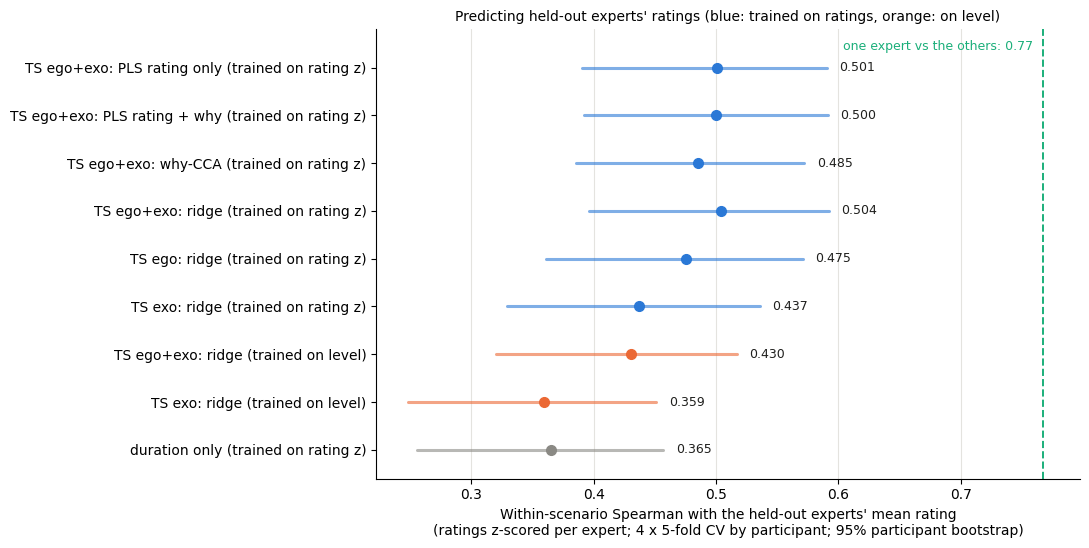

In [7]:
import matplotlib.pyplot as plt

shown = [("duration only", "rating z"), ("TS exo: ridge", "level"), ("TS ego+exo: ridge", "level"),
         ("TS exo: ridge", "rating z"), ("TS ego: ridge", "rating z"), ("TS ego+exo: ridge", "rating z"),
         ("TS ego+exo: why-CCA", "rating z"), ("TS ego+exo: PLS rating + why", "rating z"), ("TS ego+exo: PLS rating only", "rating z")]
fig, ax = plt.subplots(figsize=(11, 0.42 * len(shown) + 1.8))
for k, key in enumerate(shown):
    v, b = results[key]["vs experts z"]
    lo, hi = np.nanquantile(b, [0.025, 0.975])
    color = "#8a8984" if key[0] == "duration only" else ("#eb6834" if key[1] == "level" else "#2a78d6")
    ax.plot([lo, hi], [k, k], color=color, lw=2.2, alpha=0.6, solid_capstyle="round")
    ax.plot(v, k, "o", color=color, ms=7)
    ax.text(hi + 0.01, k, f"{v:.3f}", va="center", fontsize=9, color="#1f1f1d")
hv = results["human: one expert"]["vs experts z"][0]
ax.axvline(hv, color="#1baf7a", ls="--", lw=1.4)
ax.text(hv - 0.008, len(shown) - 0.55, f"one expert vs the others: {hv:.2f}", color="#1baf7a", fontsize=9, ha="right", va="center")
ax.set_xlim(right=max(hv + 0.03, ax.get_xlim()[1]))
ax.set_yticks(range(len(shown)), [f"{r} (trained on {t})" for r, t in shown])
ax.set_ylim(-0.6, len(shown) - 0.2)
ax.set_xlabel("Within-scenario Spearman with the held-out experts' mean rating\n(ratings z-scored per expert; 4 x 5-fold CV by participant; 95% participant bootstrap)")
ax.grid(axis="x", color="#e4e3df"); ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.set_title("Predicting held-out experts' ratings (blue: trained on ratings, orange: on level)", fontsize=10)
fig.tight_layout()
fig.savefig("figures/expert_rating.png", dpi=150)
plt.show()